In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
from itertools import combinations

## level 1: example

In [2]:
# exploration objective: visualise vieta's formulae by testing it against an algorithmic computation of the same sums

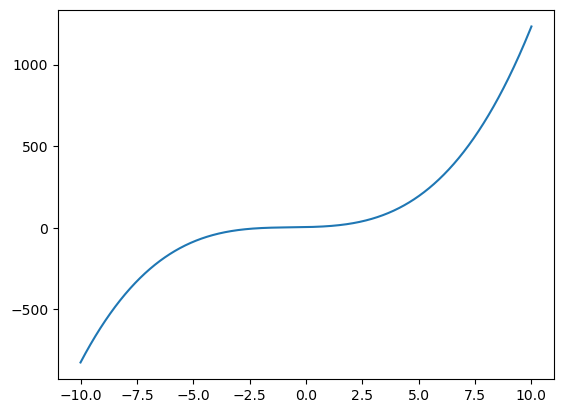

In [3]:
b = 2
c = 3
d = 4

p = Polynomial([d,c,b,1])
x = np.linspace(-10, 10, 1000)
plt.plot(x, p(x), label='P(x)')
plt.show()

### sum of roots

In [4]:
sum_vieta = -b
print(f'Sum of roots (according to Vieta\'s formulae): {sum_vieta}')

Sum of roots (according to Vieta's formulae): -2


In [5]:
# manual

roots=p.roots()
print(roots)
sum_calc = np.sum(roots)

[-1.65062919+0.j         -0.1746854 -1.54686889j -0.1746854 +1.54686889j]


In [6]:
# error = predicted - calculated
error_sum = sum_vieta - sum_calc
print(error_sum)

(8.881784197001252e-16+0j)


### pairwise products

In [7]:
pair_products_calc = 0

for j in combinations (roots, 2):
    pair_products_calc = pair_products_calc + np.prod(j)

print(pair_products_calc)

pair_products_vieta = c
error_pair_products = pair_products_vieta - pair_products_calc
print(error_pair_products)

(2.999999999999999+0j)
(8.881784197001252e-16+0j)


### product of roots

In [8]:
product = np.prod(roots)

product_vieta = -d

error_product = product_vieta - product
print(error_product)

(-4.440892098500626e-16+0j)


### analysis

In [9]:
total_error = abs(error_sum) + abs(error_pair_products) + abs(error_product)
print(total_error)

# that's practically zero, but how does it compare to different coefficients for the same polynomial?

2.220446049250313e-15


## level 2: automation

In [10]:
# exploration objective: we've visualised and confirmed vieta's formulae, and we've identified that there is an error, though it is minute. does that error change with the coefficients? if so, how?
# to check that, we need a dataset. so, we need to code a faster way to calculate the relevant quantities

In [11]:
data = []

In [12]:
def test_vieta():
    a = float(input("Please enter the coefficient of x\u00b3."))
    while a == 0:
        print("Please enter a non-zero real value.")
        a = float(input("Please enter the coefficient of x\u00b3."))
    b = float(input("Please enter the coefficient of x\u00b2."))
    c = float(input("Please enter the coefficient of x."))
    d = float(input("Please enter the constant value."))
    p = Polynomial([d,c,b,a])
    # sum of roots
    predicted_sum = -b/a
    roots=p.roots()
    calculated_sum = np.sum(roots)
    error_sum = predicted_sum - calculated_sum
    # pairwise products
    calculated_pairs = 0
    for j in combinations (roots, 2):
        calculated_pairs = calculated_pairs + np.prod(j)
    predicted_pairs = c/a
    error_pair_products = predicted_pairs - calculated_pairs
    # product
    calculated_product = np.prod(roots)
    predicted_product = -d/a
    error_product = predicted_product - calculated_product
    # total error
    total_error = abs(error_sum) + abs(error_pair_products) + abs(error_product)
    # enter data into an array
    results = [a, b, c, d, float(error_sum), float(error_pair_products), float(error_product), float(total_error)]
    data.append(results)
    return results

In [13]:
# running my iterations and commenting the code out
# test_vieta() # coeffs 1, -6, 11, -6; three distinct real roots
# test_vieta() # coeffs 1, 0, 1, 1; one real root, two complex roots
# test_vieta() # coeffs 1, 0, -3, 2; repeated roots
# test_vieta() # coeffs 2, -4, -10, 12; non monic cubic

In [14]:
# used this to check my list, commenting the code out
# print(data)

In [15]:
# creating the dataframe, commenting the code out
# df = pd.DataFrame(data, columns=[
    # "a", "b", "c", "d", "error_sum", "error_pairs", "error_product", "total_error"])

# Source - https://stackoverflow.com/a/24284680
# Posted by Piotr Migdal, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-10, License - CC BY-SA 4.0
# adding the first experiment

# df.loc[-1] = [1, 2, 3, 4, complex(8.881784197001252e-16+0j), complex(8.881784197001252e-16+0j), complex(-4.440892098500626e-16+0j), float(2.220446049250313e-15)]  # adding a row
# df.index = df.index + 1  # shifting index
# df = df.sort_index()  # sorting by index


# df.to_csv("vieta_experiments.csv", index=False)

In [16]:
# saved the data, now open the dataframe
df = pd.read_csv("vieta_experiments.csv")
df

,a,b,c,d,error_sum,error_pairs,error_product,total_error
0,(1+0j),(2+0j),(3+0j),(4+0j),(8.881784197001252e-16+0j),(8.881784197001252e-16+0j),(-4.440892098500626e-16+0j),(2.220446049250313e-15+0j)
1,(1+0j),(-6+0j),(11+0j),(-6+0j),0j,(5.329070518200751e-15+0j),(5.329070518200751e-15+0j),(1.0658141036401503e-14+0j)
2,(1+0j),0j,(1+0j),(1+0j),(-4.440892098500626e-16+0j),(-2.6645352591003757e-15+0j),(1.3322676295501878e-15+0j),(4.440892098500626e-15+0j)
3,(1+0j),0j,(-3+0j),(2+0j),(-2.220446049250313e-16+0j),(-2.6645352591003757e-15+0j),(-2.886579864025407e-15+0j),(5.773159728050814e-15+0j)
4,(2+0j),(-4+0j),(-10+0j),(12+0j),(8.881784197001252e-16+0j),(3.552713678800501e-15+0j),(7.993605777301127e-15+0j),(1.2434497875801753e-14+0j)


## level 3: analyse the preliminary data

In [17]:
# exploration objective: we have a small dataset. now, we make a preliminary exploration on how the coefficients of a cubic polynomial affect 
# the numerical accuracy of the sums calculated by python, with vieta's formulae as a baseline

In [18]:
# need all the dataframe values as float numbers
df = df.map(lambda x: complex(x).real if isinstance(x, str) and 'j' in x else x)
df = df.astype(float)

In [19]:
# our errors are currently signed, create columns for absolute error
df["error_sum_abs"] = df["error_sum"].abs()
df["error_pairs_abs"] = df["error_pairs"].abs()
df["error_product_abs"] = df["error_product"].abs()

df

,a,b,c,d,error_sum,error_pairs,error_product,total_error,error_sum_abs,error_pairs_abs,error_product_abs
0,1.0,2.0,3.0,4.0,8.881784e-16,8.881784e-16,-4.440892e-16,2.220446e-15,8.881784e-16,8.881784e-16,4.440892e-16
1,1.0,-6.0,11.0,-6.0,0.000000e+00,5.329071e-15,5.329071e-15,1.065814e-14,0.000000e+00,5.329071e-15,5.329071e-15
2,1.0,0.0,1.0,1.0,-4.440892e-16,-2.664535e-15,1.332268e-15,4.440892e-15,4.440892e-16,2.664535e-15,1.332268e-15
3,1.0,0.0,-3.0,2.0,-2.220446e-16,-2.664535e-15,-2.886580e-15,5.773160e-15,2.220446e-16,2.664535e-15,2.886580e-15
4,2.0,-4.0,-10.0,12.0,8.881784e-16,3.552714e-15,7.993606e-15,1.243450e-14,8.881784e-16,3.552714e-15,7.993606e-15


In [20]:
# create dictionaries with the relevant data

mean_errors = {'sum':float(df["error_sum_abs"].mean()), 'pairs':float(df["error_pairs_abs"].mean()), 'product':float(df["error_product_abs"].mean())}
print(mean_errors)

median_errors = {'sum':float(df["error_sum_abs"].median()), 'pairs':float(df["error_pairs_abs"].median()), 'product':float(df["error_product_abs"].median())}
print(median_errors)

max_errors = {'sum':float(df["error_sum_abs"].max()), 'pairs':float(df["error_pairs_abs"].max()), 'product':float(df["error_product_abs"].max())}
print(max_errors)

std_errors = {'sum':float(df["error_sum_abs"].std()), 'pairs':float(df["error_pairs_abs"].std()), 'product':float(df["error_product_abs"].std())}
print(std_errors)

{'sum': 4.884981308350689e-16, 'pairs': 3.0198066269804257e-15, 'product': 3.597122599785507e-15}
{'sum': 4.440892098500626e-16, 'pairs': 2.6645352591003757e-15, 'product': 2.886579864025407e-15}
{'sum': 8.881784197001252e-16, 'pairs': 5.329070518200751e-15, 'product': 7.993605777301127e-15}
{'sum': 3.9720546451956367e-16, 'pairs': 1.6134562241441008e-15, 'product': 3.0783423500266184e-15}


Text(0.5, 1.0, 'Mean Absolute Errors Across the Vieta Relationships')

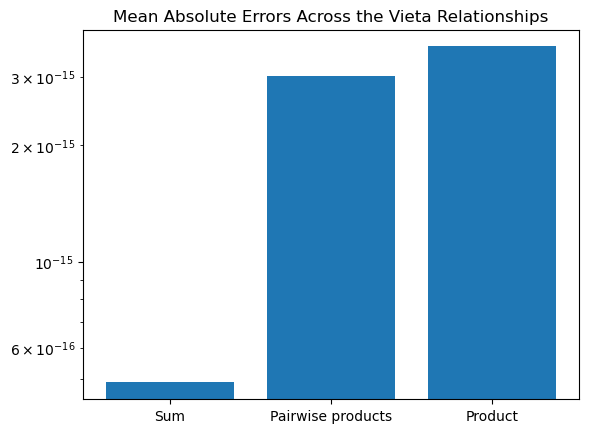

In [21]:
# let's compare the means

x = ['Sum', 'Pairwise products', 'Product']
y = [mean_errors['sum'], mean_errors['pairs'], mean_errors['product']]
plt.bar(x, y)
plt.yscale('log')
plt.title('Mean Absolute Errors Across the Vieta Relationships')

In [22]:
# let's check mean relative errors 

threshold = 1e-6   # so we don't have to divide by zero or values close to it; errors would be misleading


df['relative_error_sum_abs'] = (
    df['error_sum_abs'] / (df['b'].abs() / df['a'].abs())
)

df['relative_error_pairs_abs'] = (
    df['error_pairs_abs'] / (df['c'].abs() / df['a'].abs())
)

df['relative_error_product_abs'] = (
    df['error_product_abs'] / (df['d'].abs() / df['a'].abs())
)

# exclude zero or near-zero expected values

df.loc[(df['b'].abs() / df['a'].abs()) < threshold,
       'relative_error_sum_abs'] = np.nan

df.loc[(df['c'].abs() / df['a'].abs()) < threshold,
       'relative_error_pairs_abs'] = np.nan

df.loc[(df['d'].abs() / df['a'].abs()) < threshold,
       'relative_error_product_abs'] = np.nan

# calculate mean relative errors

mean_relative_errors = {
    'sum': float(df['relative_error_sum_abs'].mean()),
    'pairs': float(df['relative_error_pairs_abs'].mean()),
    'product': float(df['relative_error_product_abs'].mean())
}

print(mean_relative_errors)

df

{'sum': 2.9605947323337506e-16, 'pairs': 1.0087553687988089e-15, 'product': 1.021405182655144e-15}


,a,b,c,d,error_sum,error_pairs,error_product,total_error,error_sum_abs,error_pairs_abs,error_product_abs,relative_error_sum_abs,relative_error_pairs_abs,relative_error_product_abs
0,1.0,2.0,3.0,4.0,8.881784e-16,8.881784e-16,-4.440892e-16,2.220446e-15,8.881784e-16,8.881784e-16,4.440892e-16,4.440892e-16,2.960595e-16,1.110223e-16
1,1.0,-6.0,11.0,-6.0,0.000000e+00,5.329071e-15,5.329071e-15,1.065814e-14,0.000000e+00,5.329071e-15,5.329071e-15,0.000000e+00,4.844610e-16,8.881784e-16
2,1.0,0.0,1.0,1.0,-4.440892e-16,-2.664535e-15,1.332268e-15,4.440892e-15,4.440892e-16,2.664535e-15,1.332268e-15,NaN,2.664535e-15,1.332268e-15
3,1.0,0.0,-3.0,2.0,-2.220446e-16,-2.664535e-15,-2.886580e-15,5.773160e-15,2.220446e-16,2.664535e-15,2.886580e-15,NaN,8.881784e-16,1.443290e-15
4,2.0,-4.0,-10.0,12.0,8.881784e-16,3.552714e-15,7.993606e-15,1.243450e-14,8.881784e-16,3.552714e-15,7.993606e-15,4.440892e-16,7.105427e-16,1.332268e-15


Text(0.5, 1.0, 'Mean Relative Errors Across the Vieta Relationships')

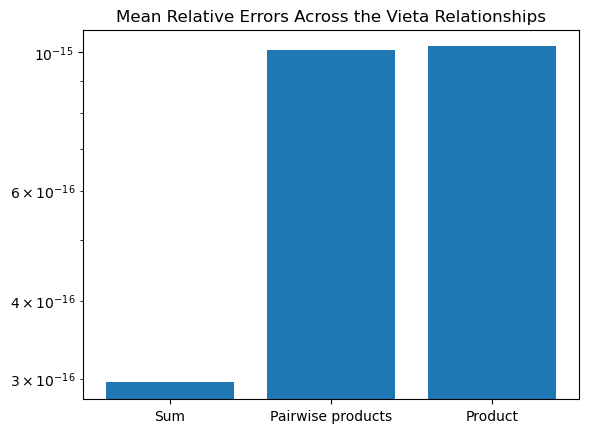

In [23]:
# graph mean relative errors

x = ['Sum', 'Pairwise products', 'Product']
y = [mean_relative_errors['sum'], mean_relative_errors['pairs'], mean_relative_errors['product']]
plt.bar(x, y)
plt.yscale('log')
plt.title('Mean Relative Errors Across the Vieta Relationships')

In [24]:
# sum appears to have the smallest error (probably because it involves the least operations so the least rounding by python)
# to test that, we need a much larger dataset

## level 4: expansion

In [25]:
# exploration objective: we believe that the magnitudes of both absolute and relative errors are sum<pairs<products. now, we need a larger dataset to test that across coefficients

In [26]:
# create a list to hold the functions
dataset = []

In [27]:
# tweak the existing function

def trial_vieta():
    a = float(np.random.uniform(-100, 100))
    while a == 0:
        a = float(np.random.uniform(-100, 100))
    b = float(np.random.uniform(-100, 100))
    c = float(np.random.uniform(-100, 100))
    d = float(np.random.uniform(-100, 100))
    p = Polynomial([d,c,b,a])
    # sum of roots
    predicted_sum = -b/a
    roots=p.roots()
    calculated_sum = np.sum(roots)
    error_sum = predicted_sum - calculated_sum
    # pairwise products
    calculated_pairs = 0
    for j in combinations (roots, 2):
        calculated_pairs = calculated_pairs + np.prod(j)
    predicted_pairs = c/a
    error_pairs = predicted_pairs - calculated_pairs
    # product
    calculated_product = np.prod(roots)
    predicted_product = -d/a
    error_product = predicted_product - calculated_product
    # absolute errors
    error_sum_abs = abs(error_sum)
    error_pairs_abs = abs(error_pairs)
    error_product_abs = abs(error_product)
    # relative errors
    threshold = 1e-6        # so we don't have to divide by zero or values close to it; errors would be misleading
    if abs(b/a) < threshold:
        relative_error_sum_abs = np.nan
    else:
        relative_error_sum_abs = abs(error_sum)/((abs(b))/(abs(a)))
    if abs(c/a) < threshold:
        relative_error_pairs_abs = np.nan
    else:
        relative_error_pairs_abs = abs(error_pairs)/((abs(c))/(abs(a)))
    if abs(d/a) < threshold:
        relative_error_product_abs = np.nan
    else:
        relative_error_product_abs = abs(error_product)/((abs(d))/(abs(a)))
    # enter data into an array
    results = [a, b, c, d, error_sum_abs, error_pairs_abs, error_product_abs, abs(relative_error_sum_abs), abs(relative_error_pairs_abs), abs(relative_error_product_abs)]
    dataset.append(results)

In [28]:
# commenting the relevant code out

# dataset = []  # reset the list just in case

# for i in range(1000):
    # trial_vieta()

# i didn't record the seed when i generated the polynomials but the dataset can be retrieved from the csv

# dataset = pd.DataFrame(dataset, columns=[
    # "a", "b", "c", "d", "error_sum_abs", "error_pairs_abs", "error_product_abs", "relative_error_sum_abs", "relative_error_pairs_abs", "relative_error_product_abs"])

# dataset.to_csv("vieta_dataset.csv", index=False)

dataset = pd.read_csv("vieta_dataset.csv")
print(dataset.shape)
dataset.sample(5)

(1000, 10)


,a,b,c,d,error_sum_abs,error_pairs_abs,error_product_abs,relative_error_sum_abs,relative_error_pairs_abs,relative_error_product_abs
606,58.940405,73.897231,-14.888991,33.360881,4.440892e-16,6.661338e-16,2.220446e-16,3.542054e-16,2.636995e-15,3.922978e-16
172,50.155941,-98.428901,13.050320,-46.303815,8.881784e-16,5.551115e-17,2.220446e-16,4.525848e-16,2.133445e-16,2.405170e-16
718,16.809953,89.176749,-81.845654,70.527610,0.000000e+00,3.552714e-15,5.329071e-15,0.000000e+00,7.296777e-16,1.270161e-15
152,-47.511992,-83.988091,72.433161,-73.712540,1.776357e-15,1.110223e-15,1.110223e-15,1.004884e-15,7.282425e-16,7.156029e-16
312,7.958562,71.781689,29.408764,48.155739,1.776357e-15,1.776357e-15,2.664535e-15,1.969478e-16,4.807154e-16,4.403602e-16


## level 5: expanded analysis

In [29]:
# exploration objective: we've created a sufficiently large dataset. now we want to check whether the relationships we observed in the errors(sum<pairs<product for absolute, sum<product<pairs for relative) holds here as well

In [30]:
# create dictionaries with the relevant data

mean_errors = {'sum':float(dataset["error_sum_abs"].mean()), 'pairs':float(dataset["error_pairs_abs"].mean()), 'product':float(dataset["error_product_abs"].mean())}
print(mean_errors)

median_errors = {'sum':float(dataset["error_sum_abs"].median()), 'pairs':float(dataset["error_pairs_abs"].median()), 'product':float(dataset["error_product_abs"].median())}
print(median_errors)

max_errors = {'sum':float(dataset["error_sum_abs"].max()), 'pairs':float(dataset["error_pairs_abs"].max()), 'product':float(dataset["error_product_abs"].max())}
print(max_errors)

std_errors = {'sum':float(dataset["error_sum_abs"].std()), 'pairs':float(dataset["error_pairs_abs"].std()), 'product':float(dataset["error_product_abs"].std())}
print(std_errors)

mean_relative_errors = {'sum':float(dataset["relative_error_sum_abs"].mean()), 'pairs':float(dataset["relative_error_pairs_abs"].mean()), 'product':float(dataset["relative_error_product_abs"].mean())}
print(mean_relative_errors)

median_relative_errors = {'sum':float(dataset["relative_error_sum_abs"].median()), 'pairs':float(dataset["relative_error_pairs_abs"].median()), 'product':float(dataset["relative_error_product_abs"].median())}
print(median_relative_errors)

max_relative_errors = {'sum':float(dataset["relative_error_sum_abs"].max()), 'pairs':float(dataset["relative_error_pairs_abs"].max()), 'product':float(dataset["relative_error_product_abs"].max())}
print(max_relative_errors)

std_relative_errors = {'sum':float(dataset["relative_error_sum_abs"].std()), 'pairs':float(dataset["relative_error_pairs_abs"].std()), 'product':float(dataset["relative_error_product_abs"].std())}
print(std_relative_errors)

{'sum': 7.038798797293077e-16, 'pairs': 2.5211985277273642e-15, 'product': 3.2484800298615114e-15}
{'sum': 4.440892098500626e-16, 'pairs': 7.2164496600635185e-16, 'product': 5.551115123125784e-16}
{'sum': 5.684341886080803e-14, 'pairs': 5.684341886080801e-13, 'product': 7.958078640513122e-13}
{'sum': 1.942759610588618e-15, 'pairs': 2.026806682208766e-14, 'product': 2.896762757328179e-14}
{'sum': 1.6176287088250239e-15, 'pairs': 2.9780434879348354e-15, 'product': 8.309245542079066e-16}
{'sum': 3.9937366258753556e-16, 'pairs': 7.300950470049439e-16, 'product': 6.610781436311551e-16}
{'sum': 1.509684722387419e-13, 'pairs': 3.690660486551424e-13, 'product': 1.3542939507202995e-14}
{'sum': 7.525746296440219e-15, 'pairs': 1.8223084540375148e-14, 'product': 8.505872696970099e-16}


Text(0.5, 1.0, 'Mean Absolute Errors Across the Vieta Relationships')

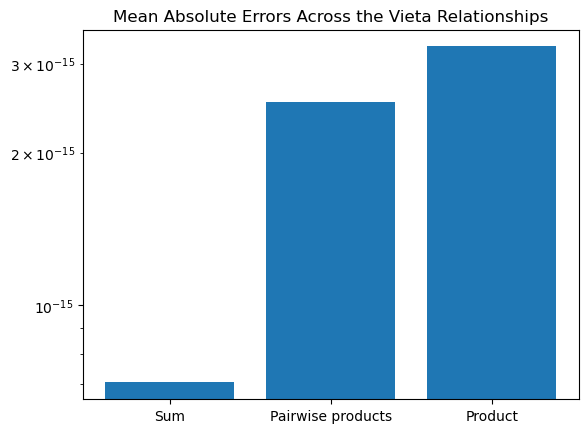

In [31]:
# let's compare the means for the absolute errors

x = ['Sum', 'Pairwise products', 'Product']
y = [mean_errors['sum'], mean_errors['pairs'], mean_errors['product']]
plt.bar(x, y)
plt.yscale('log')
plt.title('Mean Absolute Errors Across the Vieta Relationships')

Text(0.5, 1.0, 'Mean Relative Errors Across the Vieta Relationships')

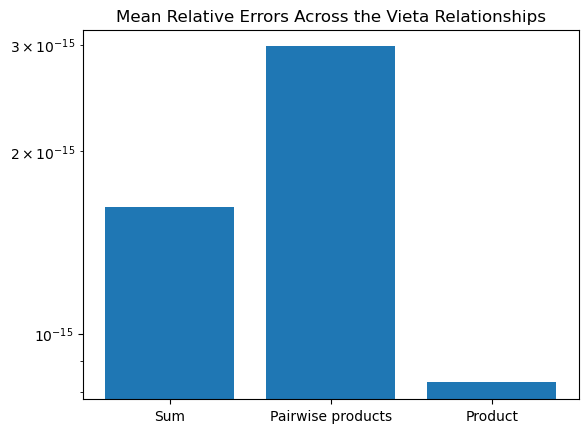

In [32]:
# let's compare the means for the relative errors

x = ['Sum', 'Pairwise products', 'Product']
y = [mean_relative_errors['sum'], mean_relative_errors['pairs'], mean_relative_errors['product']]
plt.bar(x, y)
plt.yscale('log')
plt.title('Mean Relative Errors Across the Vieta Relationships')

In [33]:
# we need to remember that there may have been some NaN values

count_nan_sum = dataset['relative_error_sum_abs'].isna().sum()
print("Number of NaN values in sum:", count_nan_sum)

count_nan_pairs = dataset['relative_error_pairs_abs'].isna().sum()
print("Number of NaN values in pairs:", count_nan_pairs)

count_nan_product = dataset['relative_error_product_abs'].isna().sum()
print("Number of NaN values in product:", count_nan_product)

Number of NaN values in sum: 0
Number of NaN values in pairs: 0
Number of NaN values in product: 0


Text(0.5, 1.0, 'Median Absolute Errors Across the Vieta Relationships')

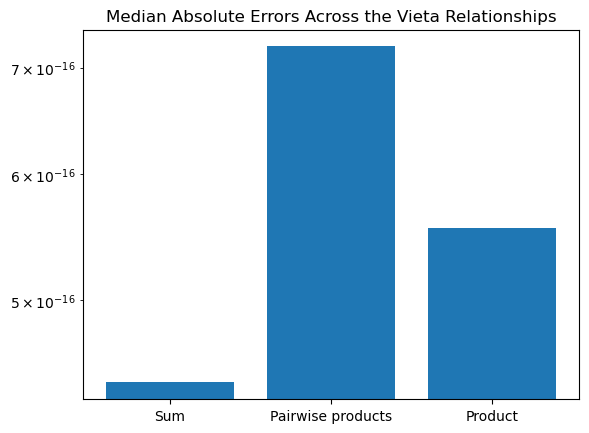

In [34]:
# let's look at the medians

x = ['Sum', 'Pairwise products', 'Product']
y = [median_errors['sum'], median_errors['pairs'], median_errors['product']]
plt.bar(x, y)
plt.yscale('log')
plt.title('Median Absolute Errors Across the Vieta Relationships')

Text(0.5, 1.0, 'Median Relative Errors Across the Vieta Relationships')

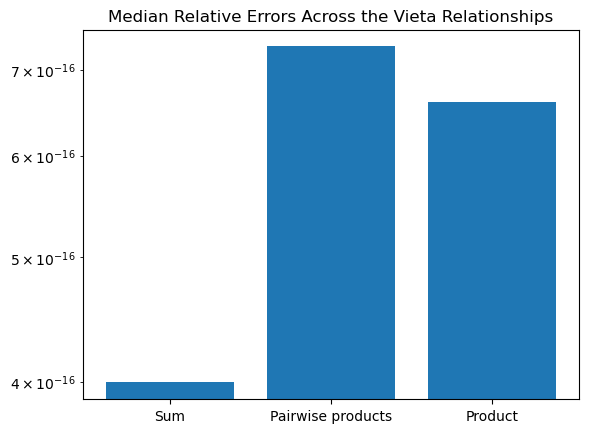

In [35]:
x = ['Sum', 'Pairwise products', 'Product']
y = [median_relative_errors['sum'], median_relative_errors['pairs'], median_relative_errors['product']]
plt.bar(x, y)
plt.yscale('log')
plt.title('Median Relative Errors Across the Vieta Relationships')

## level 6: conclusion

In [ ]:
# so, the mean absolute errors preserved the initial relationship, but the mean relative errors turned out to be product<sum<pairs rather than sum<pairs<products
# if i had to guess with my current knowledge of computational math, i'd hypothesise that the absolute errors turned out that way since sums are (generally) smaller than pairs which are smaller than products, the rounding errors for them were also respectively small
# and for relative errors, it made sense to me to hypothesise that multiplication is more accurate than/gives less rounding error than sums (amd pairs has more sums than the sum calculation, making this hold)
# but when we consider the medians (sum<product<pairs and sum<product<pairs respectively), it's interesting that we get the same relationship
# it makes sense to me that absolute error for products had a lot of substantially larger values and there were substantially larger in all the relative errors (because the max. errors are rather larger than the medians)
# from this i want to hypothesise that the reason is due to the number of computations performed? like sum and product are just two computations vs pair being five (three multiplications and two sums), as well as the fact that products tend to be larger values than sums of the same values
# we do have to remember that this isn't representative of ALL cubics because our coefficient ranges are limited and so is the sample size
# we also didn't sort by the "type" of cubic, such as how many real roots they had
# also do remember that i have very little knowledge into computational math so i'm just guessing from the results i see. i'm making basic hypotheses at my current high school level and am not trying to explain or state anything
# i was surprised by the fact that we had no NaN values at all but i suppose it isn't all that strange since it's a very small chance for one to occur
# but at the end of the day, these errors are insanely minute. it's crazy to think that computers are this accurate
# i also definitely can say that i understand vieta's formulas a lot better now!